# 21 人体姿态与动作：从真实视频到33点骨架与关节角度

    这是接在19课之后的真实场景实验。你将看到原图、人工标注、自动检测ROI、裁剪与坐标变换、真实预训练CNN内部的卷积/激活/降采样、向量、关键点坐标、误差，以及逐帧视频结果。

    **运行前说明**：沿用项目已有依赖，无需安装MediaPipe包。使用OpenCV Zoo发布的MediaPipe ONNX模型和其Apache-2.0预处理代码；首次联网下载约26MB模型与少量真实样例，以后可离线复用。OpenCV DNN本课使用CPU。Notebook已嵌入实际输出。

    本课**不从头训练关键点大模型**，也不把预测当成人工真值。COCO-WholeBody人工标注用于核对坐标与误差；Google示例照片和TensorFlow.js真实视频用于新输入推理。预训练模型可能见过公开数据，不能把这里的误差称为严格独立测试集成绩。

In [1]:
from pathlib import Path
import sys, json, csv
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import cv2, numpy as np, matplotlib.pyplot as plt
from course_utils import setup, save_figure
from keypoint_utils import (prepare_keypoints, models, trace_network, plot_channels,
    draw_points, HAND_EDGES, BODY_EDGES, COCO_TO_MP, joint_angle, finger_state,
    export_inventory, infer_video)
setup()
DATA = prepare_keypoints()
PREFIX = '21_pose'
detector, estimator = models('pose')
annotations = json.loads((DATA/'test_coco_wholebody.json').read_text())
print('OpenCV版本', cv2.__version__, '预训练网络固定权重；实际推理CPU')
print('人工标注照片', len(annotations['images']), '人物标注', len(annotations['annotations']))

OpenCV版本 4.12.0 预训练网络固定权重；实际推理CPU
人工标注照片 4 人物标注 14


## 1. 标注文件到底记录什么

    图像左上角是原点，x向右，y向下。像素坐标与归一化坐标不能混用：u=x/W，v=y/H。框采用左上角加宽高xywh；画框前转换为xyxy。

    COCO-WholeBody的身体是17点，每只手21点，点数组按x,y,v排列。v=0未标注，v=1已标注但遮挡，v=2可见；未标注点不能参与监督误差。这里保存原始JSON和可检索的坐标CSV，不把坐标写死在图片里。

/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGR

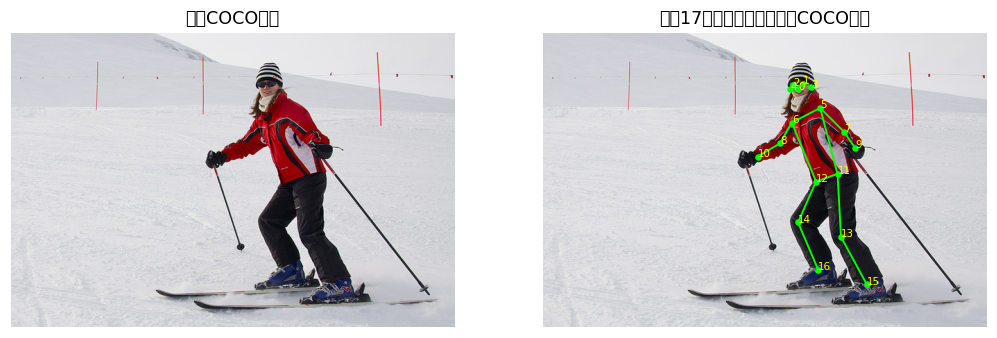

原始框xywh
[280.79, 44.73, 218.7, 346.68]
前5个人工坐标x,y,v
[[367.  81.   2.]
 [374.  73.   2.]
 [360.  75.   2.]
 [386.  78.   2.]
 [356.  81.   2.]]


In [2]:
ann = next(a for a in annotations['annotations'] if a['id'] == 442619)
gt = np.array(ann['keypoints'], np.float32).reshape(17, 3)
gt_image = cv2.imread(str(DATA/(str(ann['image_id']).zfill(12)+'.jpg')))
mask = gt[:, 2] > 0
coco_edges = [(5,6),(5,7),(7,9),(6,8),(8,10),(5,11),(6,12),(11,12),(11,13),(13,15),(12,14),(14,16)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(gt_image, cv2.COLOR_BGR2RGB)); axes[0].set_title('真实COCO原图'); axes[0].axis('off')
draw_points(axes[1], gt_image, gt, coco_edges, '人工17点标注：黄色编号为COCO编号', visible=mask)
save_figure(PREFIX+'_annotation')
print('原始框xywh', ann['bbox'], '前5个人工坐标x,y,v', gt[:5], sep='\n')

MediaPipe模型输出33个主体点，本模型还带6个辅助点，共39×5数值；COCO监督只有17个点。两套编号不同，不能直接把第i行相减。代码显式定义COCO→MediaPipe映射，再只比较已标注的二维坐标；这里没有三维人工真值，不能拿相对深度z计算“真实3D准确率”。

In [3]:
with (ROOT/'outputs'/(PREFIX+'_ground_truth.csv')).open('w', newline='', encoding='utf-8-sig') as out:
    writer = csv.writer(out); writer.writerow(['keypoint_id','x_pixel','y_pixel','visibility','x_over_width','y_over_height'])
    for i,(x,y,v) in enumerate(gt):
        writer.writerow([i,float(x),float(y),int(v),float(x/gt_image.shape[1]),float(y/gt_image.shape[0])])
print('人工标注坐标已导出，不包含预测值')

人工标注坐标已导出，不包含预测值


## 2. 新图输入：先检测ROI，再缩放进入关键点网络

    原图是H×W×3的BGR。检测器先找手掌/人体，关键点网络再处理其ROI。检测框不是类别概率“变出来”的，检测器有自己的位置输出头与后处理。

    ROI会裁剪、补黑边和旋转；输入关键点网络前转RGB、除255。ONNX接口是NHWC，进入卷积后变成NCHW。尺寸缩小是采样和特征计算，不等同于“逐渐模糊”；有的通道专门强化边缘或局部结构。

原图BGR (425, 640, 3) ROI原图坐标 [320.2  36.2 448.2 164.2]
模型输入NHWC (1, 256, 256, 3) 数值范围 0.0 0.9411764740943909


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 26032 (\N{CJK UNIFIED IDEOGRAPH-65B0}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 20837 (\N{CJK UNIFIED IDEOGRAPH-5165}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 35009 (\N{CJK UNIFIED IDEOGRAPH-88C1}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21098 (\N{CJK UNIFIED IDEOGR

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26032 (\N{CJK UNIFIED IDEOGRAPH-65B0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20837 (\N{CJK UNIFIED IDEOGRAPH-5165}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 35009 (\N{CJK UNIFIED IDEOGRAPH-88C1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

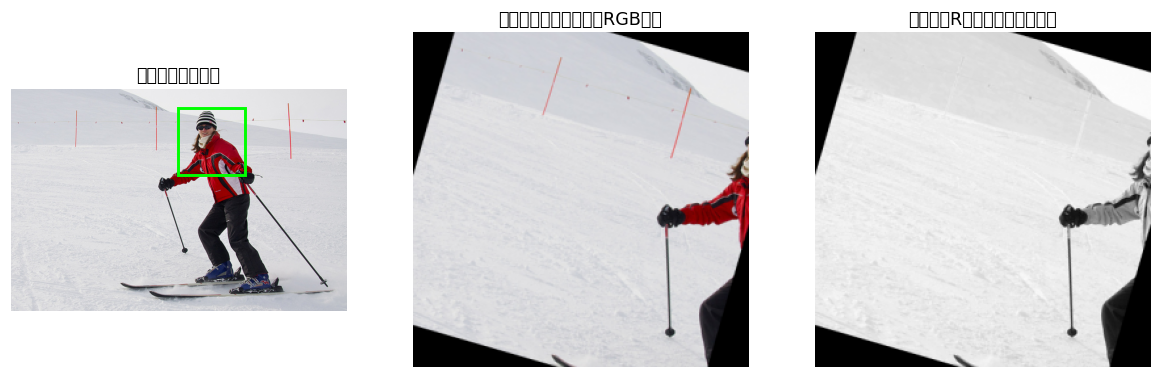

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/21_pose_input_roi.png')

In [4]:
new_image = cv2.imread(str(DATA/'000000000785.jpg'))
rois = detector.infer(new_image)
if not len(rois): raise RuntimeError('未检测到ROI，请使用一张清晰且完整的图')
roi = rois[0]
result = estimator.infer(new_image, roi)
if result is None: raise RuntimeError('关键点置信度低于阈值，不应强行补造坐标')
preprocessed = estimator._preprocess(new_image, roi)
blob = preprocessed[0]
print('原图BGR', new_image.shape, 'ROI原图坐标', np.round(roi[:4],1))
print('模型输入NHWC', blob.shape, '数值范围', float(blob.min()), float(blob.max()))
fig, axes = plt.subplots(1,3,figsize=(14,5))
axes[0].imshow(cv2.cvtColor(new_image,cv2.COLOR_BGR2RGB)); axes[0].set_title('新输入：真实原图')
x0,y0,x1,y1=roi[:4]
axes[0].add_patch(plt.Rectangle((x0,y0),x1-x0,y1-y0,fill=False,color='lime',lw=2))
axes[1].imshow(blob[0]); axes[1].set_title('裁剪、旋转、补边后的RGB输入')
axes[2].imshow(blob[0,:,:,0],cmap='gray');axes[2].set_title('单独查看R通道（不是灰度图）')
for ax in axes:ax.axis('off')
save_figure(PREFIX+'_input_roi')

## 3. 打开网络：所有算子与真实张量形状

    关闭OpenCV的算子融合，以免卷积与激活合并后看不见中间值。下面取的是同一输入实际前向计算的各层输出，不是对原图重复做模糊滤波。

    全部算子名、权重尺寸和输出尺寸写入CSV。为了能阅读，图中展示早期全部24通道，以及后续尺度的前24通道；每张图明确标注实际总通道数，未展示的数值仍可在outputs列表中索引。不同层使用各自的色阶，同一层通道共用色阶。

In [5]:
names, activations, inventory = trace_network(estimator.model, blob)
export_inventory(inventory, ROOT/'outputs'/(PREFIX+'_operators.csv'))
convs=[i for i,row in enumerate(inventory) if row['type']=='Convolution']
first=convs[0]
pools=[i for i,row in enumerate(inventory) if row['type']=='Pooling']
for row in inventory:
    print(row['index'], row['type'], tuple(row['shape']), '权重', row['weights'])
print('完整算子名称见', PREFIX+'_operators.csv')

0 Padding (1, 258, 258, 3) 权重 []
1 Permute (1, 3, 258, 258) 权重 []
2 Convolution (1, 24, 128, 128) 权重 [[24, 3, 3, 3], [24, 1]]
3 ReLU6 (1, 24, 128, 128) 权重 []
4 Convolution (1, 24, 128, 128) 权重 [[24, 1, 3, 3], [24, 1]]
5 ReLU6 (1, 24, 128, 128) 权重 []
6 Convolution (1, 8, 128, 128) 权重 [[8, 24, 1, 1], [8, 1]]
7 Convolution (1, 8, 128, 128) 权重 [[8, 1, 3, 3], [8, 1]]
8 ReLU6 (1, 8, 128, 128) 权重 []
9 Convolution (1, 8, 128, 128) 权重 [[8, 8, 1, 1], [8, 1]]
10 NaryEltwise (1, 8, 128, 128) 权重 []
11 ReLU6 (1, 8, 128, 128) 权重 []
12 Convolution (1, 32, 128, 128) 权重 [[32, 8, 1, 1], [32, 1]]
13 ReLU6 (1, 32, 128, 128) 权重 []
14 Convolution (1, 32, 64, 64) 权重 [[32, 1, 3, 3], [32, 1]]
15 ReLU6 (1, 32, 64, 64) 权重 []
16 Convolution (1, 16, 64, 64) 权重 [[16, 32, 1, 1], [16, 1]]
17 Convolution (1, 96, 64, 64) 权重 [[96, 16, 1, 1], [96, 1]]
18 ReLU6 (1, 96, 64, 64) 权重 []
19 Convolution (1, 96, 64, 64) 权重 [[96, 1, 3, 3], [96, 1]]
20 ReLU6 (1, 96, 64, 64) 权重 []
21 Convolution (1, 16, 64, 64) 权重 [[16, 96, 1, 1], [

## 4. 第一层卷积核：3个颜色通道如何合成1个特征通道

    第一层有24个3×3×3卷积核，权重形状为24×3×3×3。每个输出通道对R、G、B三个3×3小块分别乘加，再把3个结果和偏置相加。卷积不是把图“变成一个核”：**核是训练得到的参数，特征图才是图像经过核的输出**。

    模型中的BatchNorm已经折叠进卷积权重与偏置；本课展示的是ONNX实际部署权重。下面手算某一个输出像素，并与网络输出作数值校验。

/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 26680 (\N{CJK UNIFIED IDEOGRAPH-6838}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26680 (\N{CJK UNIFIED IDEOGRAPH-6838}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


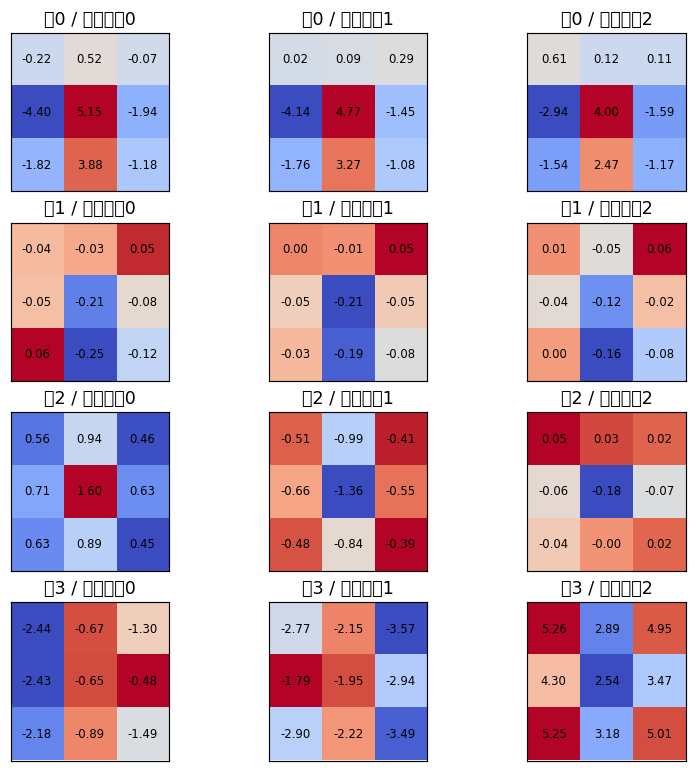

每个颜色通道贡献 [0. 0. 0.] 偏置 0.29443359375
实际输入索引起点 (19, 19) 手算 0.29443359375 网络 0.29443359375 误差 0.0


/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 31532 (\N{CJK UNIFIED IDEOGRAPH-7B2C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 23618 (\N{CJK UNIFIED IDEOGRAPH-5C42}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 21367 (\N{CJK UNIFIED IDEOGRAPH-5377}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 31215 (\N{CJK UNIFIED IDEOGRAPH-79EF}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu 

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 31532 (\N{CJK UNIFIED IDEOGRAPH-7B2C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 23618 (\N{CJK UNIFIED IDEOGRAPH-5C42}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21367 (\N{CJK UNIFIED IDEOGRAPH-5377}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

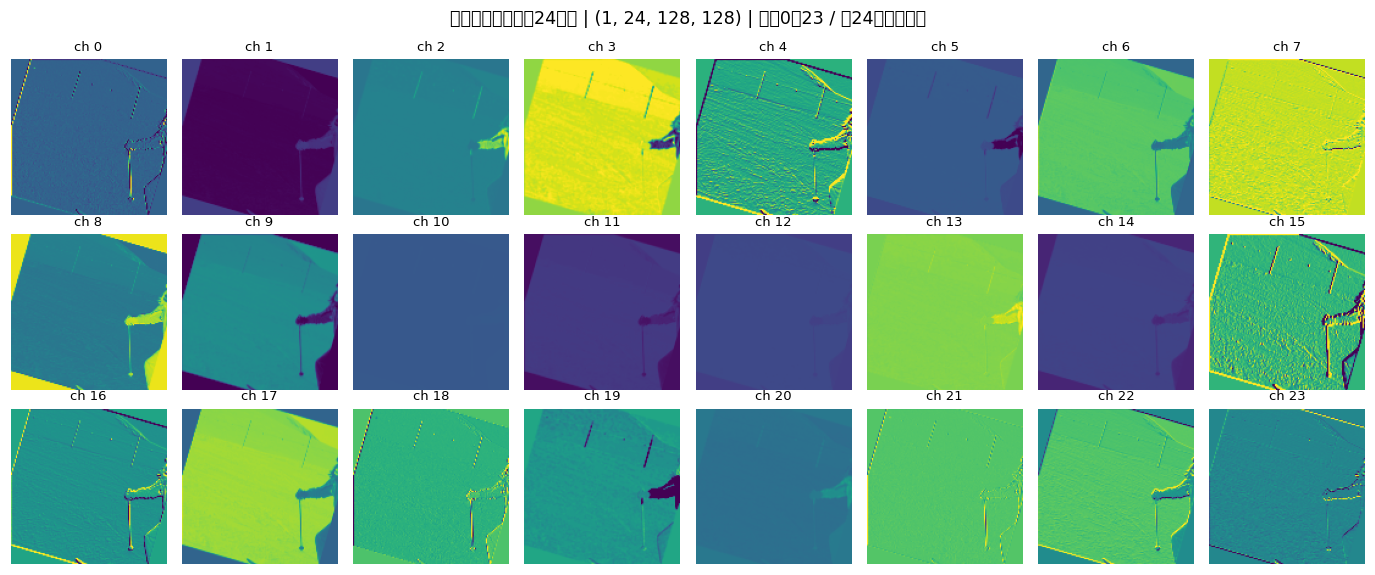

/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 25130 (\N{CJK UNIFIED IDEOGRAPH-622A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 26029 (\N{CJK UNIFIED IDEOGRAPH-65AD}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 21040 (\N{CJK UNIFIED IDEOGRAPH-5230}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 25130 (\N{CJK UNIFIED IDEOGRAPH-622A}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 26029 (\N{CJK UNIFIED IDEOGRAPH-65AD}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-cou

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 25130 (\N{CJK UNIFIED IDEOGRAPH-622A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26029 (\N{CJK UNIFIED IDEOGRAPH-65AD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21040 (\N{CJK UNIFIED IDEOGRAPH-5230}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


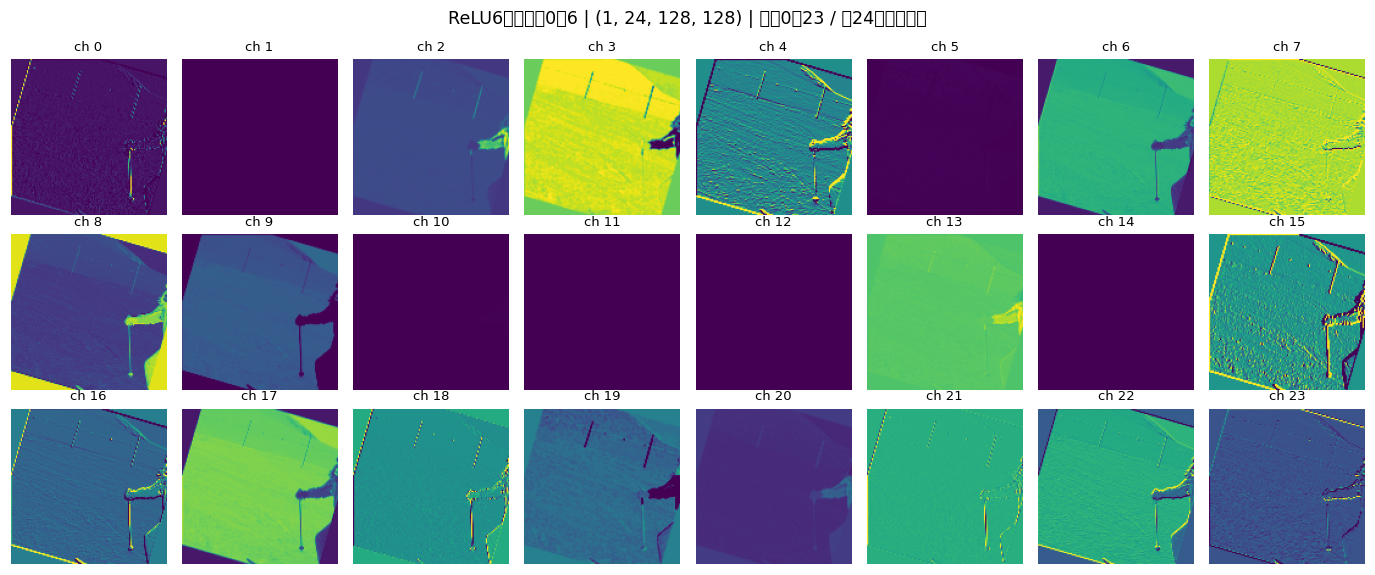

In [6]:
layer = estimator.model.getLayer(estimator.model.getLayerId(names[first]))
weights,bias = layer.blobs
fig,axes=plt.subplots(4,3,figsize=(9,9))
for k in range(4):
    for c in range(3):
        ax=axes[k,c];ax.imshow(weights[k,c],cmap='coolwarm')
        ax.set_title(f'核{k} / 输入通道{c}')
        for y in range(3):
            for x in range(3):ax.text(x,y,f'{weights[k,c,y,x]:.2f}',ha='center',va='center',fontsize=8)
        ax.set_xticks([]);ax.set_yticks([])
save_figure(PREFIX+'_kernels')
# 使用真实卷积前一层的NCHW张量；stride=2。比对两种常见边界补齐偏移。
conv_input=activations[first-1][0]
y,x=10,10
checks=[]
for offset in [-1,0]:
    patch=conv_input[:,2*y+offset:2*y+offset+3,2*x+offset:2*x+offset+3]
    terms=(patch*weights[0]).sum(axis=(1,2))
    manual=terms.sum()+bias.reshape(-1)[0]
    checks.append((abs(float(manual-activations[first][0,0,y,x])),offset,terms,manual))
error,offset,terms,manual=min(checks,key=lambda t:t[0])
assert error<1e-4
print('每个颜色通道贡献',terms,'偏置',float(bias.reshape(-1)[0]))
print('实际输入索引起点', (2*y+offset,2*x+offset), '手算',float(manual),'网络',float(activations[first][0,0,y,x]),'误差',error)
plot_channels(activations[first], '第一层卷积：全部24通道', PREFIX+'_conv1')
plot_channels(activations[first+1], 'ReLU6：截断到0至6', PREFIX+'_relu1')

## 5. 深度卷积、1×1卷积与降采样

    深度卷积的权重是C×1×K×K：每个通道各自用一个小核；1×1卷积则在同一空间位置混合多个通道，改变通道数。MobileNet风格网络常把这两步分开以减少计算量。

    ReLU6把负数置0、大于6的值截为6；它是非线性，不改变张量形状。最大池化选局部最大值；步长2卷积也能缩小空间尺寸，但同时学习权重。不能把所有尺寸下降都叫池化。

首个深度卷积权重 [24, 1, 3, 3] 输出 [1, 24, 128, 128]


/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 36880 (\N{CJK UNIFIED IDEOGRAPH-9010}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 28145 (\N{CJK UNIFIED IDEOGRAPH-6DF1}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from font

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36880 (\N{CJK UNIFIED IDEOGRAPH-9010}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 28145 (\N{CJK UNIFIED IDEOGRAPH-6DF1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


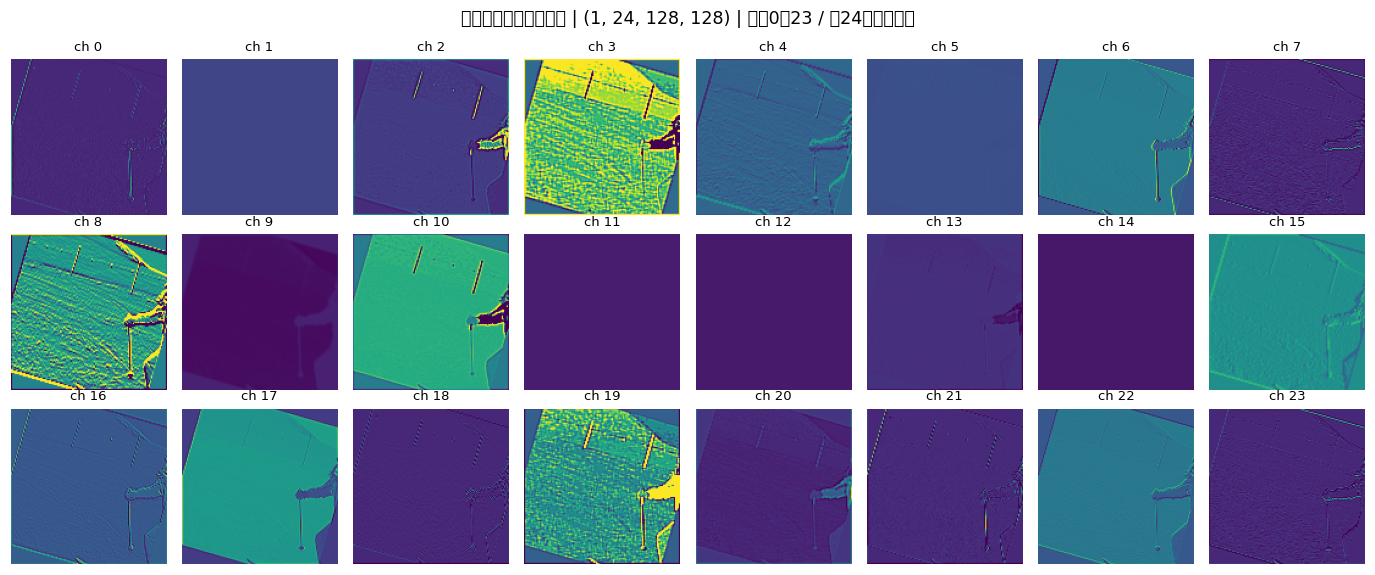

第一处池化 114 [1, 192, 4, 4]


/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 32593 (\N{CJK UNIFIED IDEOGRAPH-7F51}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 32476 (\N{CJK UNIFIED IDEOGRAPH-7EDC}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 27744 (\N{CJK UNIFIED IDEOGRAPH-6C60}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32593 (\N{CJK UNIFIED IDEOGRAPH-7F51}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32476 (\N{CJK UNIFIED IDEOGRAPH-7EDC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 27744 (\N{CJK UNIFIED IDEOGRAPH-6C60}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


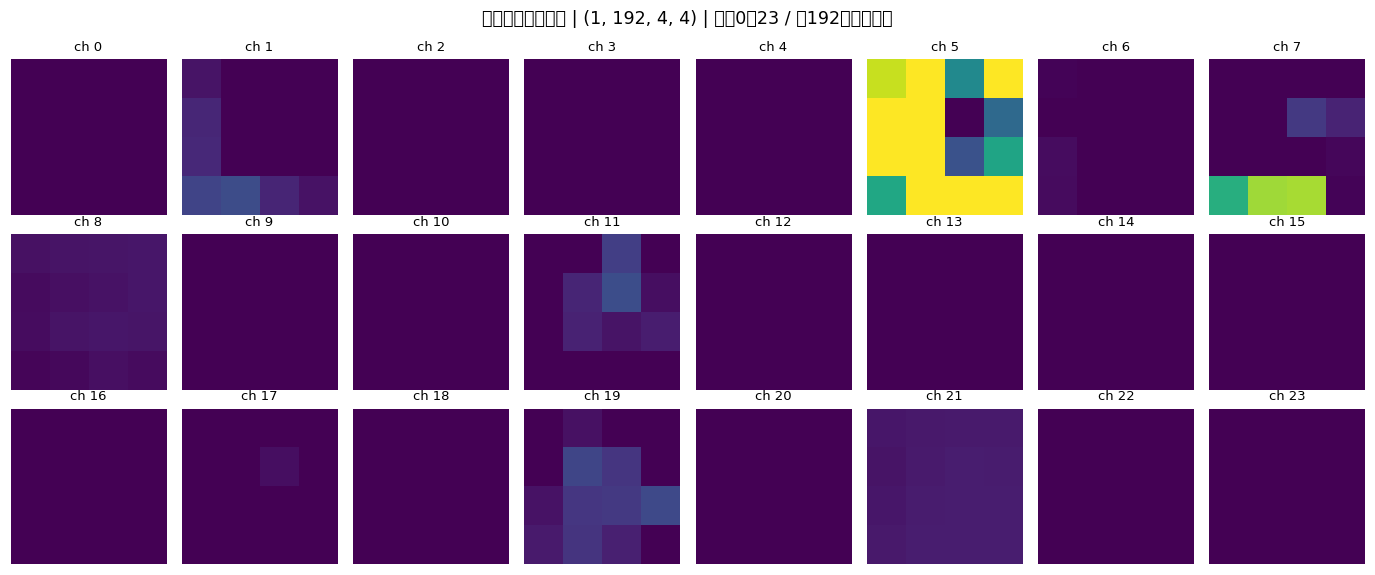

/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 21495 (\N{CJK UNIFIED IDEOGRAPH-53F7}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 31639 (\N{CJK UNIFIED IDEOGRAPH-7B97}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/keypoint_utils.py:128: UserWarning: Glyph 26356 (\N{CJK UNIFIED IDEOGRAPH-66F4}) missing from font(s) DejaVu Sans.
  fig.tight_layout()


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 31639 (\N{CJK UNIFIED IDEOGRAPH-7B97}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 26356 (\N{CJK UNIFIED IDEOGRAPH-66F4}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')


/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 31639 (\N{CJK UNIFIED IDEOGRAPH-7B97}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26356 (\N{CJK UNIFIED IDEOGRAPH-66F4}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


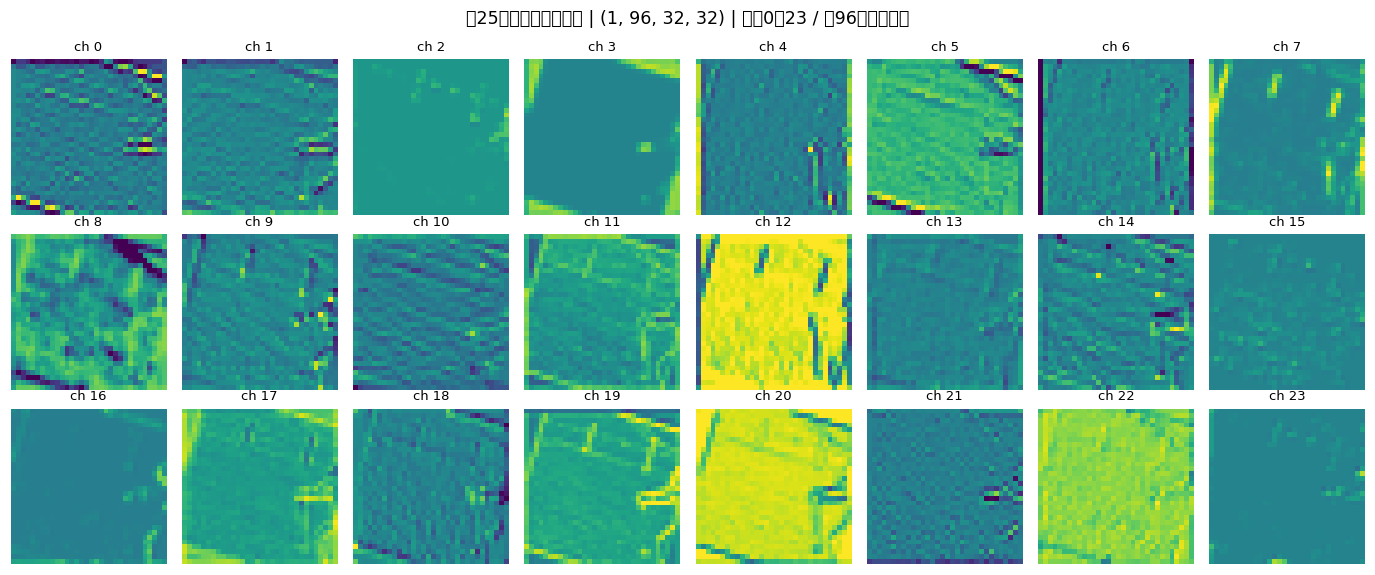

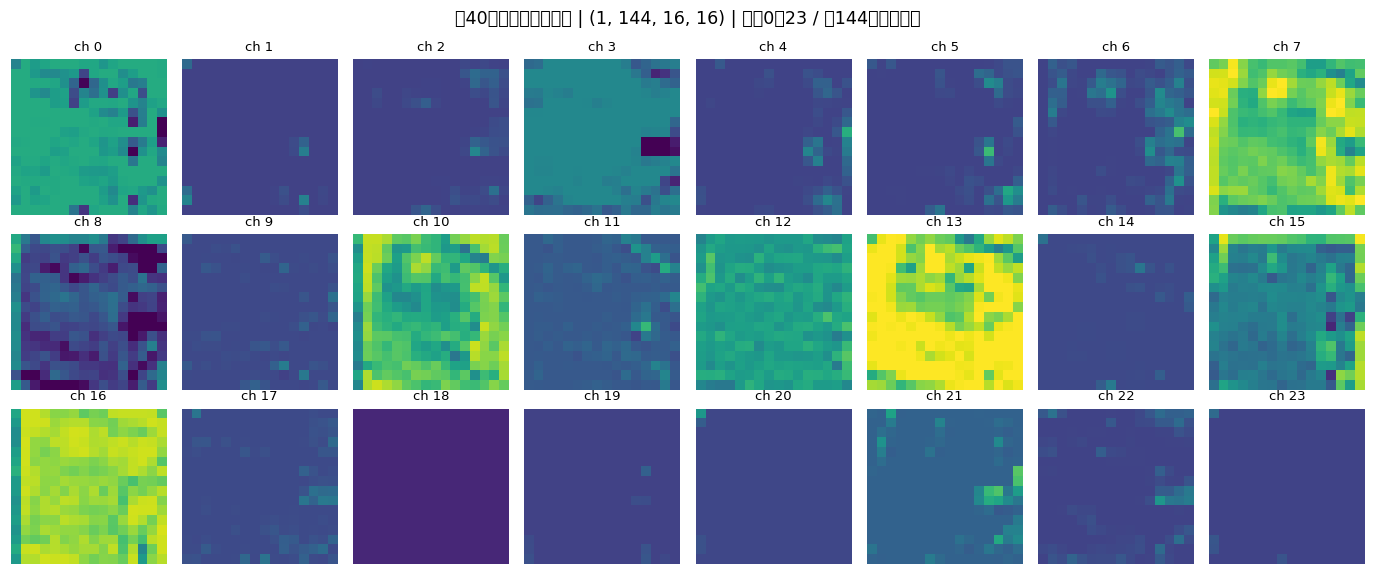

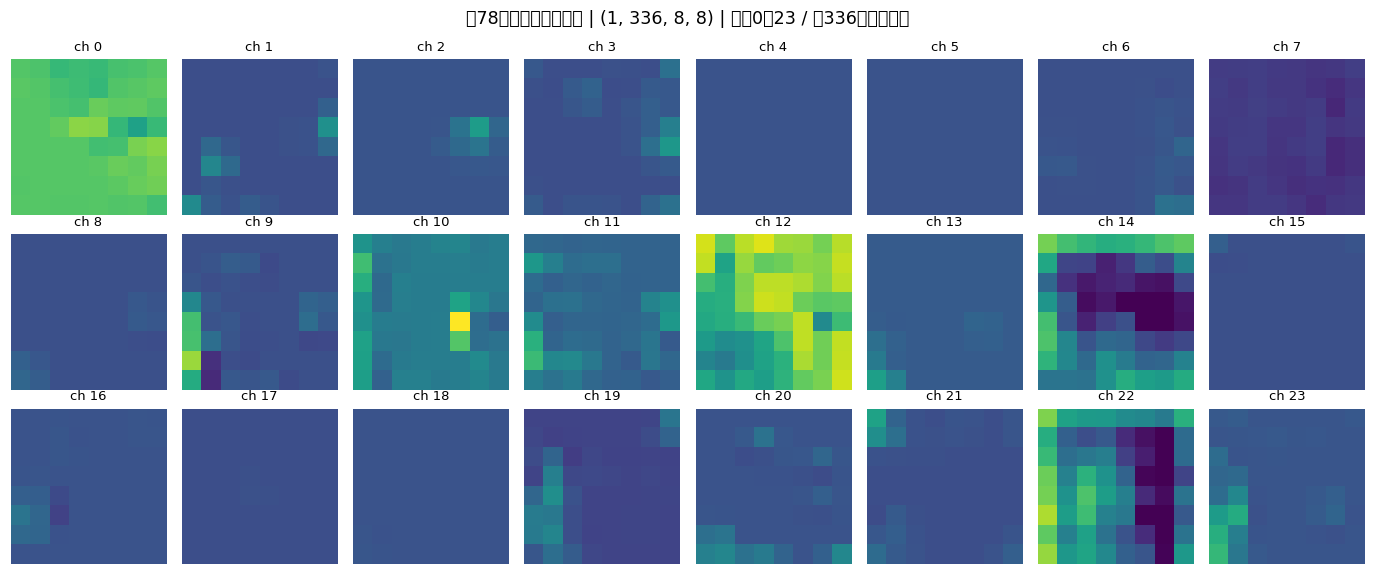

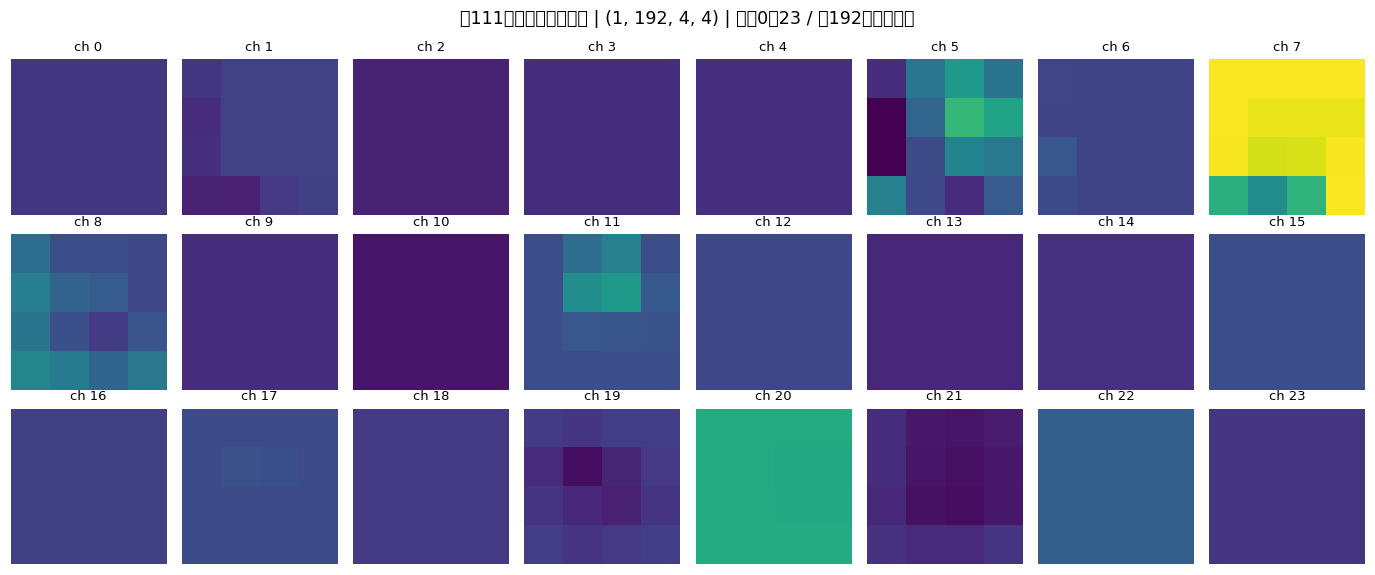

In [7]:
depth=next(i for i in convs if len(inventory[i]['weights'][0])==4 and inventory[i]['weights'][0][1]==1)
print('首个深度卷积权重', inventory[depth]['weights'][0], '输出', inventory[depth]['shape'])
plot_channels(activations[depth], '逐通道的深度卷积输出', PREFIX+'_depthwise')
if pools:
    pool=pools[0]
    print('第一处池化',pool,inventory[pool]['shape'])
    plot_channels(activations[pool], '网络真实池化输出', PREFIX+'_pool')
# 主干按空间尺度挑选第一次出现的卷积，保留真实通道数。
selected=[]; seen=set()
for i in convs:
    a=activations[i]
    if a.ndim==4 and a.shape[-1] in [56,28,14,7,32,16,8,4,2] and a.shape[-1] not in seen:
        selected.append(i);seen.add(a.shape[-1])
selected=selected[:4]
for i in selected:
    plot_channels(activations[i], f'第{i}号算子：更深一层', PREFIX+f'_stage_{i}')

## 6. 从空间特征到向量，再到坐标

    这里看实际网络的计算路径。手部模型通过全局平均池化把每个通道压成一个值，再通过全连接层输出21×3坐标。人体模型用192×2×2特征，最后一个覆盖2×2空间的卷积与“展平向量×权重”数值等价，输出39×5坐标/置信度参数。人体网络还另有热图、分割和世界坐标分支，不能把这些分支误认为一条串行管线。

In [8]:
head=next(i for i,r in enumerate(inventory) if r['type']=='Convolution' and r['weights'] and r['weights'][0]==[195,192,2,2])
# 三个并行输出头共享其前面的主干ReLU6；用最后一个192×2×2非线性输出。
candidates=[i for i in range(head) if inventory[i]['shape']==[1,192,2,2] and inventory[i]['type']=='ReLU6']
vector=activations[candidates[-1]][0].reshape(-1)
w,b=estimator.model.getLayer(estimator.model.getLayerId(names[head])).blobs
manual=w.reshape(195,-1)@vector+b.reshape(-1)
raw=activations[names.index('Identity')][0]
np.testing.assert_allclose(manual,raw,atol=2e-3,rtol=2e-4)
print('192×2×2 → 768维向量 → 195个数 → 39×5')
print('手算输出与网络最大误差',float(np.max(abs(manual-raw))))
points=result[1][:33]

192×2×2 → 768维向量 → 195个数 → 39×5
手算输出与网络最大误差 4.57763671875e-05


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 38469 (\N{CJK UNIFIED IDEOGRAPH-9645}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGR

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 38469 (\N{CJK UNIFIED IDEOGRAPH-9645}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24449 (\N{CJK UNIFIED IDEOGRAPH-5F81}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

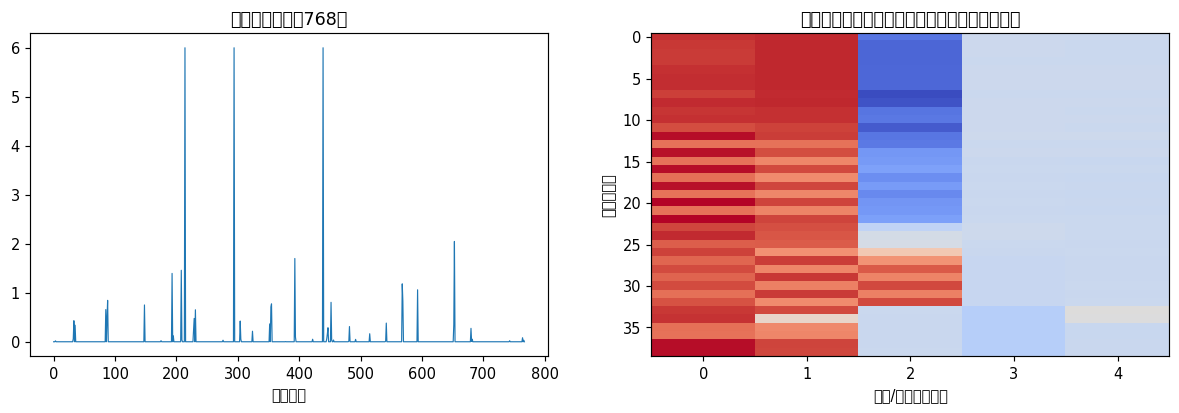

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/21_pose_vector_output.png')

In [9]:
fig,axes=plt.subplots(1,2,figsize=(14,4))
axes[0].plot(vector,lw=.8);axes[0].set_title(f'实际特征向量：{len(vector)}维');axes[0].set_xlabel('维度编号')
axes[1].imshow(raw.reshape(-1,3) if len(raw)==63 else raw.reshape(-1,5),aspect='auto',cmap='coolwarm')
axes[1].set_title('坐标输出矩阵（不同列量纲不同，仅观察数值）');axes[1].set_xlabel('坐标/可见性等分量');axes[1].set_ylabel('关键点编号')
save_figure(PREFIX+'_vector_output')

## 7. 模型坐标如何回到原图

    模型输出坐标属于旋转补边后的输入平面。必须先减去输入中心，乘ROI/输入尺寸比例，再逆旋转，最后加回ROI中心和裁剪偏移；直接乘原图宽高会错位。预处理返回的旋转矩阵和pad_bias就是为逆变换保留的。

    下面并列打印输入坐标、还原后的原图坐标与归一化坐标；画出的编号仍是模型自己的编号。x/W和y/H便于跨分辨率保存，z是模型的相对深度，不能把二维图像中的z直接当成实测距离。

/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 33258 (\N{CJK UNIFIED IDEOGRAPH-81EA}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21160 (\N{CJK UNIFIED IDEOGRAPH-52A8}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 36870 (\N{CJK UNIFIED IDEOGRAPH-9006}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 25442 (\N{CJK UNIFIED IDEOGR

预处理旋转角度（度） -16.107401220988915 补边/裁剪偏移 [0 0]
输入坐标前5行
[[142.50987 144.69247]
 [139.97453 146.25397]
 [139.11685 146.3972 ]
 [138.30621 146.5391 ]
 [142.834   146.21512]]
逆变换回原图前5行
[[363.2222    84.026215]
 [367.30206   76.79025 ]
 [369.86588   76.52657 ]
 [372.4501    76.2031  ]
 [362.0893    77.09291 ]]
归一化前5行
[[0.56753469 0.19770874]
 [0.57390947 0.18068295]
 [0.57791543 0.18006253]
 [0.58195329 0.17930142]
 [0.56576452 0.18139508]]


/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 33258 (\N{CJK UNIFIED IDEOGRAPH-81EA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21160 (\N{CJK UNIFIED IDEOGRAPH-52A8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 36870 (\N{CJK UNIFIED IDEOGRAPH-9006}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

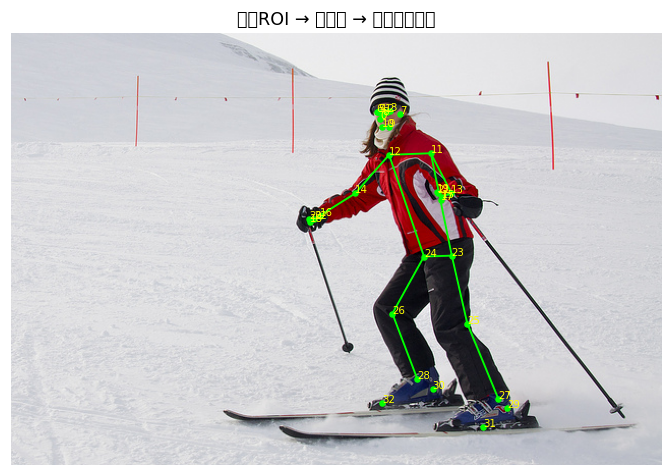

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/21_pose_prediction.png')

In [10]:
print('预处理旋转角度（度）',float(preprocessed[2]),'补边/裁剪偏移',preprocessed[4])
print('输入坐标前5行',raw.reshape(-1,5)[:5,:2],sep='\n')
print('逆变换回原图前5行',points[:5,:2],sep='\n')
norm=points[:,:2]/[new_image.shape[1],new_image.shape[0]]
print('归一化前5行',norm[:5],sep='\n')
fig,ax=plt.subplots(figsize=(8,7))
draw_points(ax,new_image,points,BODY_EDGES,'自动ROI → 关键点 → 逆变换回原图')
save_figure(PREFIX+'_prediction')

## 8. 损失：一定要和人工答案比较

    关键点回归可用可见点上的L1、L2或SmoothL1监督。这里计算归一化二维MSE和平均像素误差，用于理解监督目标。预训练模型没有在本课更新参数；这些数值不是原论文完整训练损失，也不包含没有标注的三维、分割、检测损失。

    v=0的点必须屏蔽，低置信度预测也必须报告。正确做法是先检查检测是否成功，再谈点误差，而不是忽略失败样本只报好看的分数。

In [11]:
gt_rois=detector.infer(gt_image)
difficult=estimator.infer(gt_image,gt_rois[0])
if difficult is None:raise RuntimeError('人工标注参考图的人体关键点检测失败')
pred=difficult[1][COCO_TO_MP]
gt_confidence=float(difficult[-1])
figure_edges=coco_edges
print('人体置信度',gt_confidence,'COCO→MediaPipe映射',COCO_TO_MP)

人体置信度 0.9999445676803589 COCO→MediaPipe映射 [0, 2, 5, 7, 8, 11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28]


参与监督的点 17 归一化二维MSE 0.0002776445005322063 平均像素误差 10.923096656799316


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 32511 (\N{CJK UNIFIED IDEOGRAPH-7EFF}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 32418 (\N{CJK UNIFIED IDEOGRAPH-7EA2}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 65307 (\N{FULLWIDTH SEMICOLO

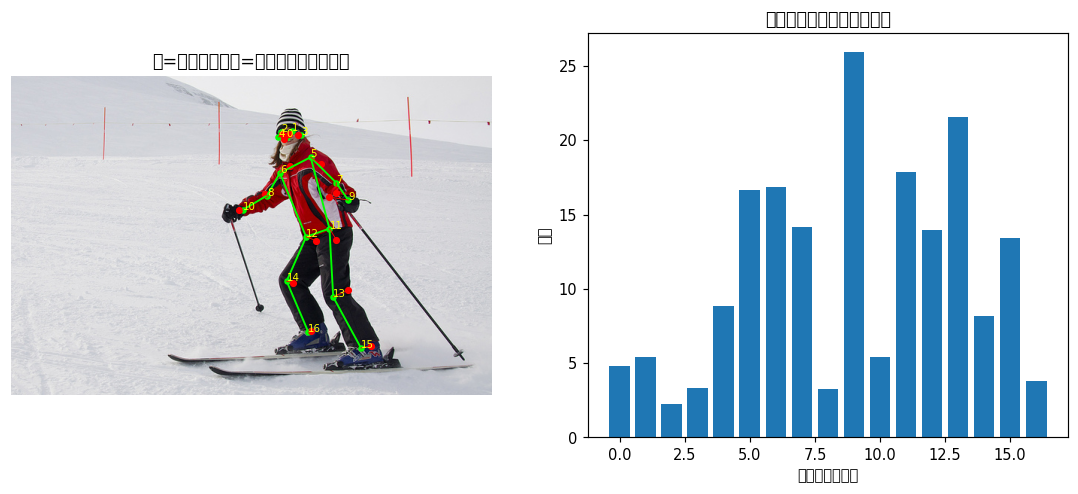

276

In [12]:
delta=pred[mask,:2]-gt[mask,:2]
squared=(delta/[gt_image.shape[1],gt_image.shape[0]])**2
mse=float(squared.mean());pixel_error=np.linalg.norm(delta,axis=1)
print('参与监督的点',int(mask.sum()),'归一化二维MSE',mse,'平均像素误差',float(pixel_error.mean()))
fig,axes=plt.subplots(1,2,figsize=(13,5))
draw_points(axes[0],gt_image,gt,figure_edges,'绿=人工标注，红=预测；保留失败情况',visible=mask)
axes[0].scatter(pred[mask,0],pred[mask,1],s=15,c='red')
for a,b in zip(gt[mask,:2],pred[mask,:2]):axes[0].plot([a[0],b[0]],[a[1],b[1]],'r-',lw=.6)
axes[1].bar(np.where(mask)[0],pixel_error);axes[1].set_title('逐个人工标注点的像素误差');axes[1].set_xlabel('人工标注点编号');axes[1].set_ylabel('像素')
save_figure(PREFIX+'_loss')
(ROOT/'outputs'/(PREFIX+'_metrics.json')).write_text(json.dumps({'reference_image_id':ann['image_id'],'annotation_id':ann['id'],
    'visible_points':int(mask.sum()),'normalized_2d_mse':mse,'mean_pixel_error':float(pixel_error.mean()),
    'confidence':gt_confidence,'evaluation':'small reference example, not independent benchmark'},indent=2),encoding='utf-8')

## 9. 姿态不等于动作：用时间序列看下蹲

        单帧输出“身体现在在哪里”，动作需要多帧。对33点中的髋、膝、踝计算膝关节夹角，就能形成随时间变化的曲线；髋膝踝接近共线时约180°，弯曲时减小。

        下面对真实下蹲视频逐帧重新检测与推理，保留帧号和时间戳。120°/160°只是本课可解释的演示阈值，不能称为医学动作评估。缺失点和低置信度用空值，不跨帧伪造补点；多个人的视频还需要身份关联，不能默认第一个框始终是同一个人。

## 10. 逐帧真实视频：帧→ROI→CNN→向量→坐标→业务输出

    此处顺序解码前80帧，每帧重新执行完整网络；不是把一张照片平移后伪装成新视频。逐帧JSON保留关键点数组与置信度，CSV便于检索和画曲线。为节省篇幅，图中每10帧展示一个快照。其他视频可替换路径；实时摄像头需要另外使用VideoCapture(0)并控制退出和隐私。

原视频fps 5.0 实际处理 65 可信检测 65


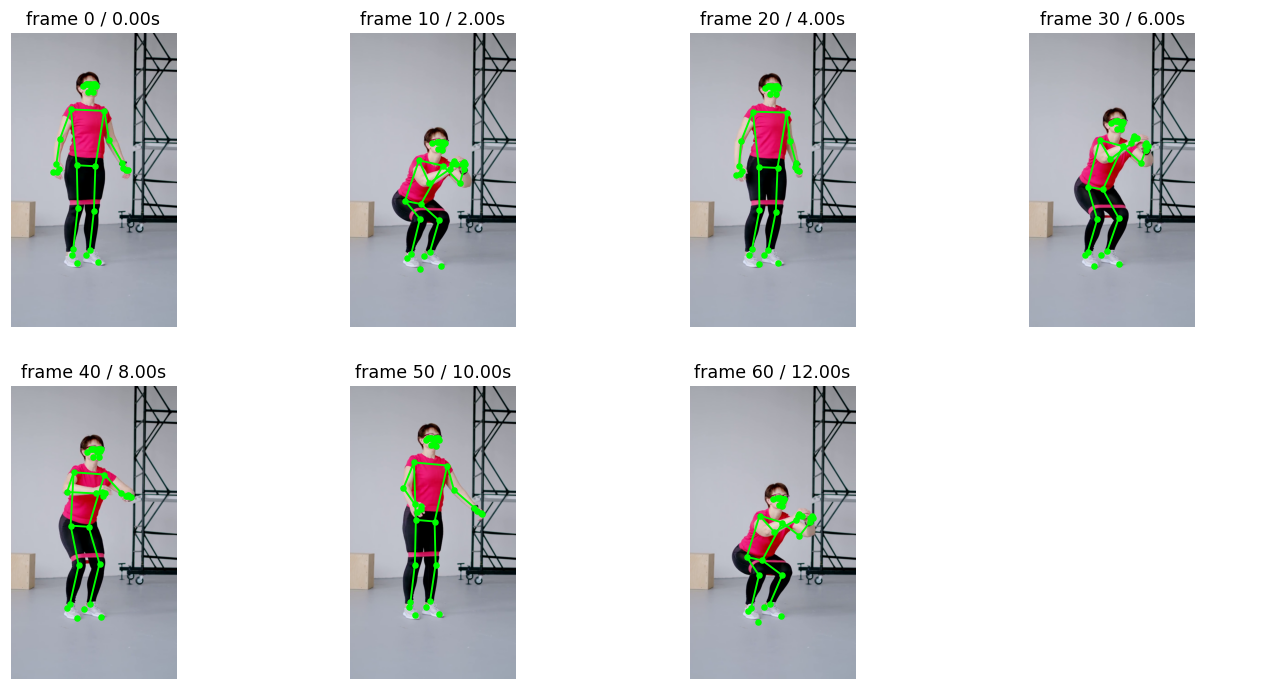

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/21_pose_video_frames.png')

In [13]:
records,snapshots,fps=infer_video(DATA/'pose_clip.mp4',detector,estimator,'pose',
    ROOT/'outputs'/(PREFIX+'_frames'),max_frames=80)
print('原视频fps',fps,'实际处理',len(records),'可信检测',sum(r['detected'] for r in records))
fig,axes=plt.subplots(2,4,figsize=(16,8))
for ax in axes.flat: ax.axis('off')
for ax,snapshot in zip(axes.flat,snapshots[:8]):
    frame,im,p,row=snapshot
    if p is not None:
        draw_points(ax,im,p,BODY_EDGES,f"frame {frame} / {row['time_s']:.2f}s",numbers=False)
    else:
        ax.imshow(cv2.cvtColor(im,cv2.COLOR_BGR2RGB));ax.set_title(f'frame {frame} 未检测');ax.axis('off')
save_figure(PREFIX+'_video_frames')

/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 33181 (\N{CJK UNIFIED IDEOGRAPH-819D}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 22841 (\N{CJK UNIFIED IDEOGRAPH-5939}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 35282 (\N{CJK UNIFIED IDEOGR

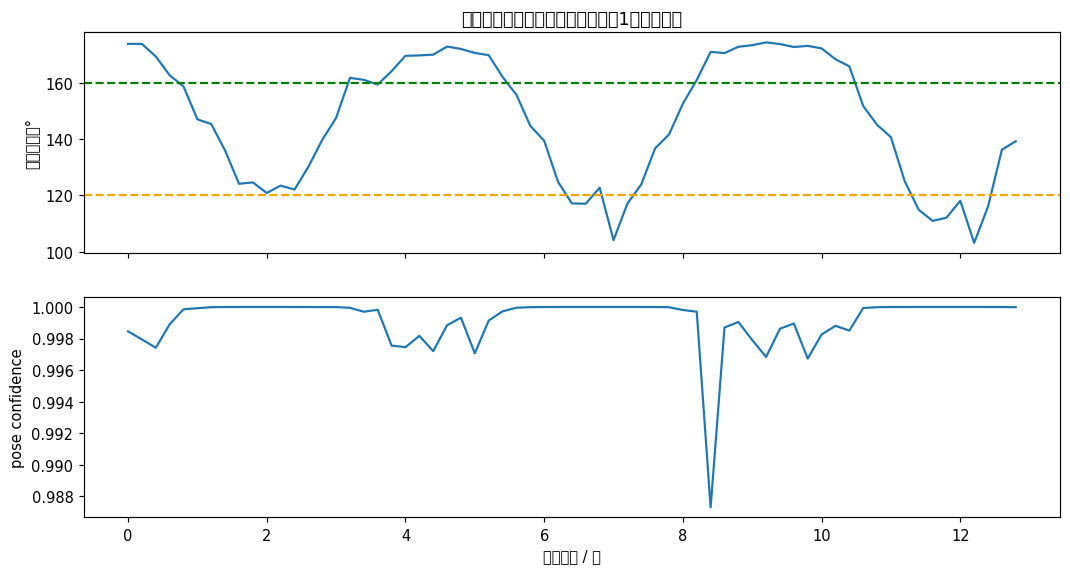

状态切换（帧号、状态） [(32, 'bent'), (41, 'standing'), (57, 'bent')]


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 24182 (\N{CJK UNIFIED IDEOGRAPH-5E76}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 34892 (\N{CJK UNIFIED IDEOGRAPH-884C}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 25903 (\N{CJK UNIFIED IDEOGR

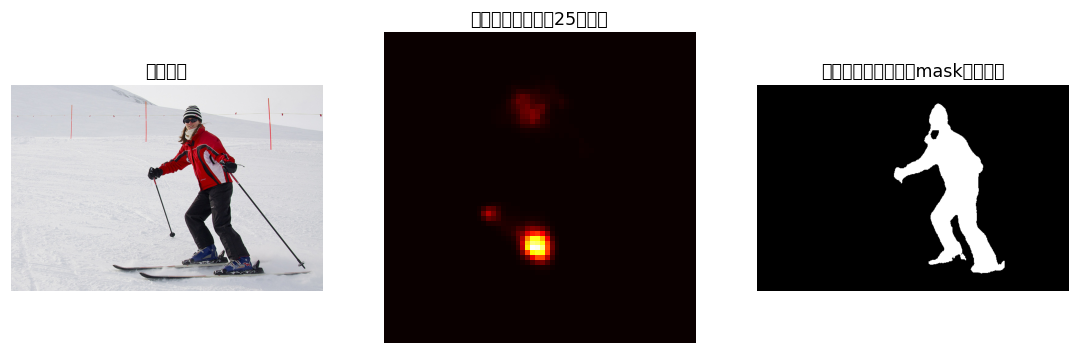

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/21_pose_heatmap_mask.png')

In [14]:
times=np.array([r['time_s'] for r in records])
angles=np.array([r.get('knee_angle',np.nan) for r in records], dtype=float)
# 有滞回的演示状态机：低于120进入弯曲，高于160恢复站立才计数。
state='standing'; repetitions=0; transitions=[]
for row,angle in zip(records,angles):
    if not np.isfinite(angle):continue
    if state=='standing' and angle<120:state='bent';transitions.append((row['frame'],'bent'))
    elif state=='bent' and angle>160:state='standing';repetitions+=1;transitions.append((row['frame'],'standing'))
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
axes[0].plot(times,angles);axes[0].axhline(120,color='orange',ls='--');axes[0].axhline(160,color='green',ls='--')
axes[0].set_title(f'真实下蹲视频：阈值状态机观测到{repetitions}次完整恢复');axes[0].set_ylabel('平均膝夹角°')
axes[1].plot(times,[r.get('confidence',np.nan) for r in records]);axes[1].set_ylabel('pose confidence');axes[1].set_xlabel('视频时间 / 秒')
save_figure(PREFIX+'_timeline')
print('状态切换（帧号、状态）',transitions)
# 一帧的39通道热图与分割支路是并行输出，演示其中膝关节热图。
fig,axes=plt.subplots(1,3,figsize=(13,4))
axes[0].imshow(new_image[:,:,::-1]);axes[0].set_title('输入原图')
heatmap=result[4][0] if result[4].ndim==4 else result[4]
axes[1].imshow(1/(1+np.exp(-np.clip(heatmap[:,:,25],-30,30))),cmap='hot');axes[1].set_title('模型并行支路：第25点热图')
axes[2].imshow(result[3],cmap='gray');axes[2].set_title('模型并行支路：人体mask（预测）')
for ax in axes:ax.axis('off')
save_figure(PREFIX+'_heatmap_mask')

## 11. 自己实践与数据划分

    1. 换一张真实照片，先检查ROI，再检查关键点落点和置信度，最后解释业务输出。
    2. 在算子CSV里任选一层，用activations[index]查看全部张量；plot_channels支持start和limit，例如start=24,limit=24查看第24至47通道，再递增start即可分批查看全部通道。
    3. 修改关节角度阈值，观察错误触发；遮挡、侧视、运动模糊都应记录失败。
    4. 如果训练自己的手势或动作分类器，以“人物/录像”为组分训练、验证、测试，禁止把相邻帧随机分到不同集合。先固定划分，再只用训练集合拟合归一化统计量；视频测试标签应另行人工核对。

    本课照片只是可重复的小型推理/标注参考，**没有用这几张照片伪造训练集或独立测试成绩**。CPU/GPU速度、三维误差、动作分类准确率、完整生产稳定性没有在此验证。

    ## 来源与权利

    - OpenCV Zoo [手部模型](https://github.com/opencv/opencv_zoo/tree/48b10fa505aeb51fbd127fc60a5c660040e823b7/models/handpose_estimation_mediapipe)、[人体模型](https://github.com/opencv/opencv_zoo/tree/48b10fa505aeb51fbd127fc60a5c660040e823b7/models/pose_estimation_mediapipe)：Apache-2.0；原版包装代码和许可在reference/opencv_zoo。
    - [COCO-WholeBody](https://github.com/jin-s13/COCO-WholeBody)人工标注，小样例来自固定版本[MMPose测试资源](https://github.com/open-mmlab/mmpose/tree/759b39c13fea6ba094afc1fa932f51dc1b11cbf9/tests/data/coco)。照片权利属于原作者，具体license字段保留在JSON，项目MIT不重新授权照片。
    - [Google官方Hand Landmarker示例](https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker)及测试照片，用作清晰新图推理。
    - [TensorFlow.js手部真实测试视频](https://github.com/tensorflow/tfjs-models/blob/c731b9ebbd6f4c9e8bf99b0df76bbdbf9c25b07f/hand-pose-detection/test_data/asl_hand.25fps.mp4)、[人体下蹲视频](https://github.com/tensorflow/tfjs-models/blob/c731b9ebbd6f4c9e8bf99b0df76bbdbf9c25b07f/pose-detection/test_data/pose_squats.mp4)。原始样例和权重按需下载到data，不混入MIT学生素材许可。

    download_manifest.json记录本次下载地址和SHA256，便于复核。工程实作应复核第三方数据许可后再分发原始图像。